# US inflation — time-varying recalibration vs benchmarks

In [28]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [29]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

os.makedirs('figures/inflation', exist_ok=True)

In [30]:
from ldf import ldf_func
from pit import pit_func, plot_pit_histograms
from uniformity_tests import uniformity_test

### Data

In [31]:
y = pd.read_excel("data/data.xlsx", sheet_name="Inflation")["Inflation"]
y_t = pd.read_excel("data/data.xlsx", sheet_name="Inflation")
y_t.rename(columns={"Unnamed: 0": "Date"}, inplace=True)
y_t['Date'] = pd.PeriodIndex(y_t['Date'], freq='Q').to_timestamp()

mean = pd.read_excel("data/data.xlsx", sheet_name="Agent Mean")[["M1", "M2", "M3", "M4"]]
vol = pd.read_excel("data/data.xlsx", sheet_name="Agent Var")[["M1", "M2", "M3", "M4"]]
dof = pd.read_excel("data/data.xlsx", sheet_name="Agent dof")[["M1", "M2", "M3", "M4"]]

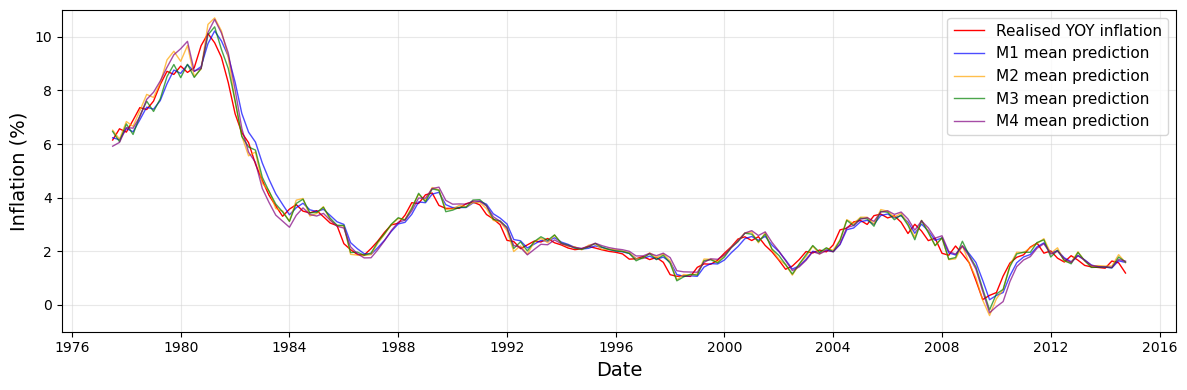

In [32]:
sns.color_palette("tab10")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pd.to_datetime(y_t["Date"]), y_t['Inflation'], color="red", lw=1, label="Realised YOY inflation")
ax.plot(pd.to_datetime(y_t["Date"]), mean["M1"], color="blue", lw=1, label="M1 mean prediction", alpha=0.7)
ax.plot(pd.to_datetime(y_t["Date"]), mean["M2"], color="orange", lw=1, label="M2 mean prediction", alpha=0.7)
ax.plot(pd.to_datetime(y_t["Date"]), mean["M3"], color="green", lw=1, label="M3 mean prediction", alpha=0.7)
ax.plot(pd.to_datetime(y_t["Date"]), mean["M4"], color="purple", lw=1, label="M4 mean prediction", alpha=0.7)
#ax.vlines(pd.to_datetime(y_t["Date"])[49], ymin=-1, ymax=12, color="grey", ls="dotted", label="calibration period")
ax.set_ylabel("Inflation (%)",fontsize=14)
ax.set_xlabel("Date",fontsize=14)
ax.grid(alpha=0.5, which='major', c='lightgrey')
ax.set_ylim(-1, 11)
ax.legend(fontsize=11)
fig.tight_layout() 
plt.show()
fig.savefig('figures/inflation/inflation plot.png',dpi=300)

In [33]:
log_lik_1 = np.asarray([stats.t(loc=mean["M1"].to_numpy()[i], scale=np.sqrt(vol["M1"].to_numpy()[i]), df=d).logpdf(y[i]) for i, d in enumerate(dof["M1"].to_numpy())])
log_lik_2 = np.asarray([stats.t(loc=mean["M2"].to_numpy()[i], scale=np.sqrt(vol["M2"].to_numpy()[i]), df=d).logpdf(y[i]) for i, d in enumerate(dof["M2"].to_numpy())])
log_lik_3 = np.asarray([stats.t(loc=mean["M3"].to_numpy()[i], scale=np.sqrt(vol["M3"].to_numpy()[i]), df=d).logpdf(y[i]) for i, d in enumerate(dof["M3"].to_numpy())])
log_lik_4 = np.asarray([stats.t(loc=mean["M4"].to_numpy()[i], scale=np.sqrt(vol["M4"].to_numpy()[i]), df=d).logpdf(y[i]) for i, d in enumerate(dof["M4"].to_numpy())])

log_lik = pd.DataFrame([log_lik_1, log_lik_2, log_lik_3, log_lik_4]).to_numpy()

In [34]:
K,T = log_lik.shape
mean_matrix =np.zeros((K,T))
vol_matrix = np.zeros((K,T))
dof_matrix = np.zeros((K,T))

for k in range(K):
    for t in range(T):
        mean_matrix[k,t] = mean.iloc[t,k]
        vol_matrix[k,t] = vol.iloc[t,k]
        dof_matrix[k,t] = dof.iloc[t,k]

### Loss Discounting Framework

In [35]:
c= 10**(-20)
discount_factors = np.array([1, 0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.001])

In [36]:
res_ldf = ldf_func(log_lik.astype(float), levels=2, discount_factors=[discount_factors, discount_factors], activation_functions=["softmax", "softmax"], c=c)
ldf_df = pd.DataFrame({'discount_factor': discount_factors, 'Mean log score': res_ldf["logscores"].mean(axis=1), 'Cumulative log score': res_ldf["logscores"].sum(axis=1)})
ldf_df.style.format("{:.3f}")

,discount_factor,Mean log score,Cumulative log score
0,1.000,-0.159,-23.855
1,0.990,-0.157,-23.576
2,0.950,-0.158,-23.635
3,0.900,-0.160,-24.031
4,0.800,-0.162,-24.346
5,0.700,-0.163,-24.478
6,0.600,-0.164,-24.553
7,0.500,-0.164,-24.602
8,0.400,-0.164,-24.638
9,0.300,-0.164,-24.666


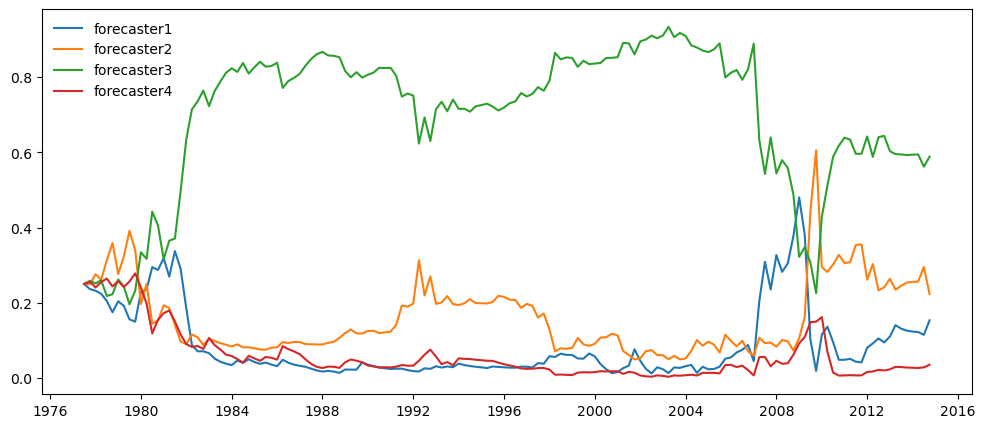

In [37]:
fig, ax = plt.subplots(figsize=(12, 5))

for i in range(log_lik.shape[0]):
    ax.plot(y_t['Date'], res_ldf["weights"][0][:,i],label= f'forecaster{i+1}')
    ax.legend(loc='upper left',fontsize=10,frameon=False)

### DMA

In [38]:
res_dma = ldf_func(log_lik.astype(float), levels=1, discount_factors=[discount_factors], activation_functions=["softmax"], c=c)
# fixed: this table previously reported res_ldf's log scores
res_dma_df = pd.DataFrame({'discount_factor': discount_factors, 'Mean log score': res_dma["logscores"].mean(axis=1), 'Cumulative log score': res_dma["logscores"].sum(axis=1)})
res_dma_df.style.format("{:.3f}")

,discount_factor,Mean log score,Cumulative log score
0,1.000,-0.152,-22.846
1,0.990,-0.152,-22.778
2,0.950,-0.150,-22.481
3,0.900,-0.156,-23.381
4,0.800,-0.166,-24.950
5,0.700,-0.172,-25.807
6,0.600,-0.175,-26.315
7,0.500,-0.178,-26.652
8,0.400,-0.179,-26.898
9,0.300,-0.181,-27.095


### X grid

In [39]:
mu_min, mu_max = y.min(), y.max()
margin = 5 * np.sqrt(vol['M1'].max())  # Use sqrt for standard deviation
x_min = mu_min - margin
x_max = mu_max + margin
M = 181
x_grid = np.linspace(x_min, x_max, M)

x_grid.shape

(181,)

### PIT and CDF

In [40]:
def compute_cdf(mean, vol, dof, x_grid,weights):

    models = ['M1', 'M2', 'M3', 'M4']
    T = len(mean)
    M = len(x_grid)
    K = len(models)
    
    cdfs = np.zeros((K, T, M))
    
    for k, model in enumerate(models):
        for t in range(T):
            # CDF at all grid points
            cdfs[k, t, :] = stats.t.cdf(
                x_grid,
                loc=mean[model].to_numpy()[t],
                scale=np.sqrt(vol[model].to_numpy()[t]),
                df=dof[model].to_numpy()[t]
            )

    linear_pool = np.einsum('ktm,ptk -> ptm', cdfs, weights)
    
    return linear_pool


cdfs = compute_cdf(mean, vol, dof, x_grid,res_ldf["weights"])

dma_cdfs = compute_cdf(mean, vol, dof, x_grid,res_dma["weights"])

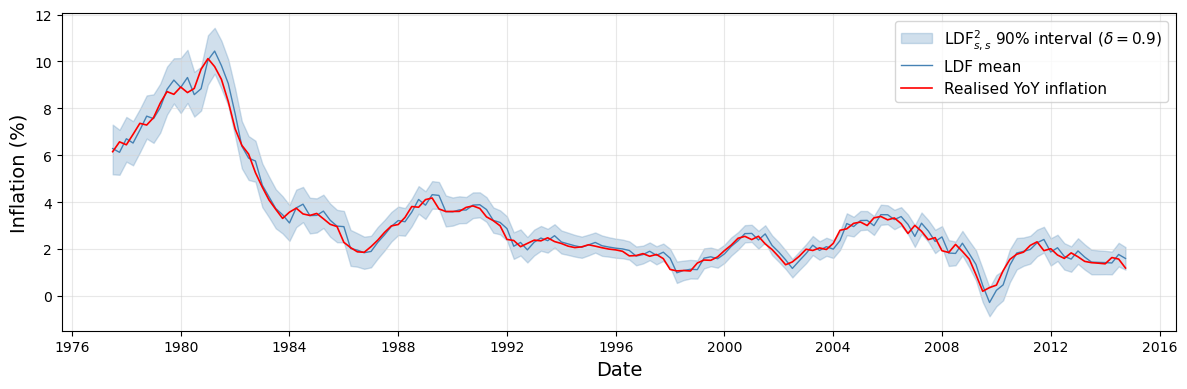

Empirical coverage of the 90% interval: 96.7%


In [41]:
d_idx = int(np.argmin(np.abs(np.asarray(discount_factors) - 0.9)))
F09 = cdfs[d_idx]                                  # (T_eval, M) pool CDF at delta = 0.9
n_eval = F09.shape[0]

def pool_quantile(F, p, grid):
    # np.interp needs an increasing x-axis; the CDF is increasing in the grid
    return np.array([np.interp(p, F[t], grid) for t in range(F.shape[0])])

q05 = pool_quantile(F09, 0.05, x_grid)
q95 = pool_quantile(F09, 0.95, x_grid)

# ALIGNMENT: the outcomes must be the same periods as the weights (fixed: offset defined first)
offset = len(y) - n_eval
W09 = res_ldf["weights"][d_idx]                                       # (n_eval, 4)
mu_eval = mean[["M1", "M2", "M3", "M4"]].to_numpy()[offset:]          # same periods as the weights
ldf_mean = np.sum(W09 * mu_eval, axis=1)                              # (n_eval,)
dates  = pd.to_datetime(y_t["Date"]).to_numpy()[offset:]
y_eval = np.asarray(y)[offset:]

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(dates, q05, q95, color="steelblue", alpha=0.25,
                label=r"LDF$^2_{s,s}$ 90% interval ($\delta=0.9$)")
ax.plot(dates, ldf_mean, color="steelblue", lw=1, label="LDF mean")
ax.plot(dates, y_eval, color="red", lw=1.2, label="Realised YoY inflation")
ax.set_ylabel("Inflation (%)", fontsize=14)
ax.set_xlabel("Date", fontsize=14)
ax.grid(alpha=0.5, which="major", c="lightgrey")
ax.legend(fontsize=11, loc="upper right")
fig.tight_layout()
fig.savefig("figures/inflation/inflation interval.png", dpi=300)   # was overwriting 'inflation plot.png'
plt.show()

print(f"Empirical coverage of the 90% interval: {np.mean((y_eval >= q05) & (y_eval <= q95)):.1%}")

In [42]:
pit_values = pit_func(cdfs, x_grid, y)

dma_pit_values = pit_func(dma_cdfs, x_grid, y)

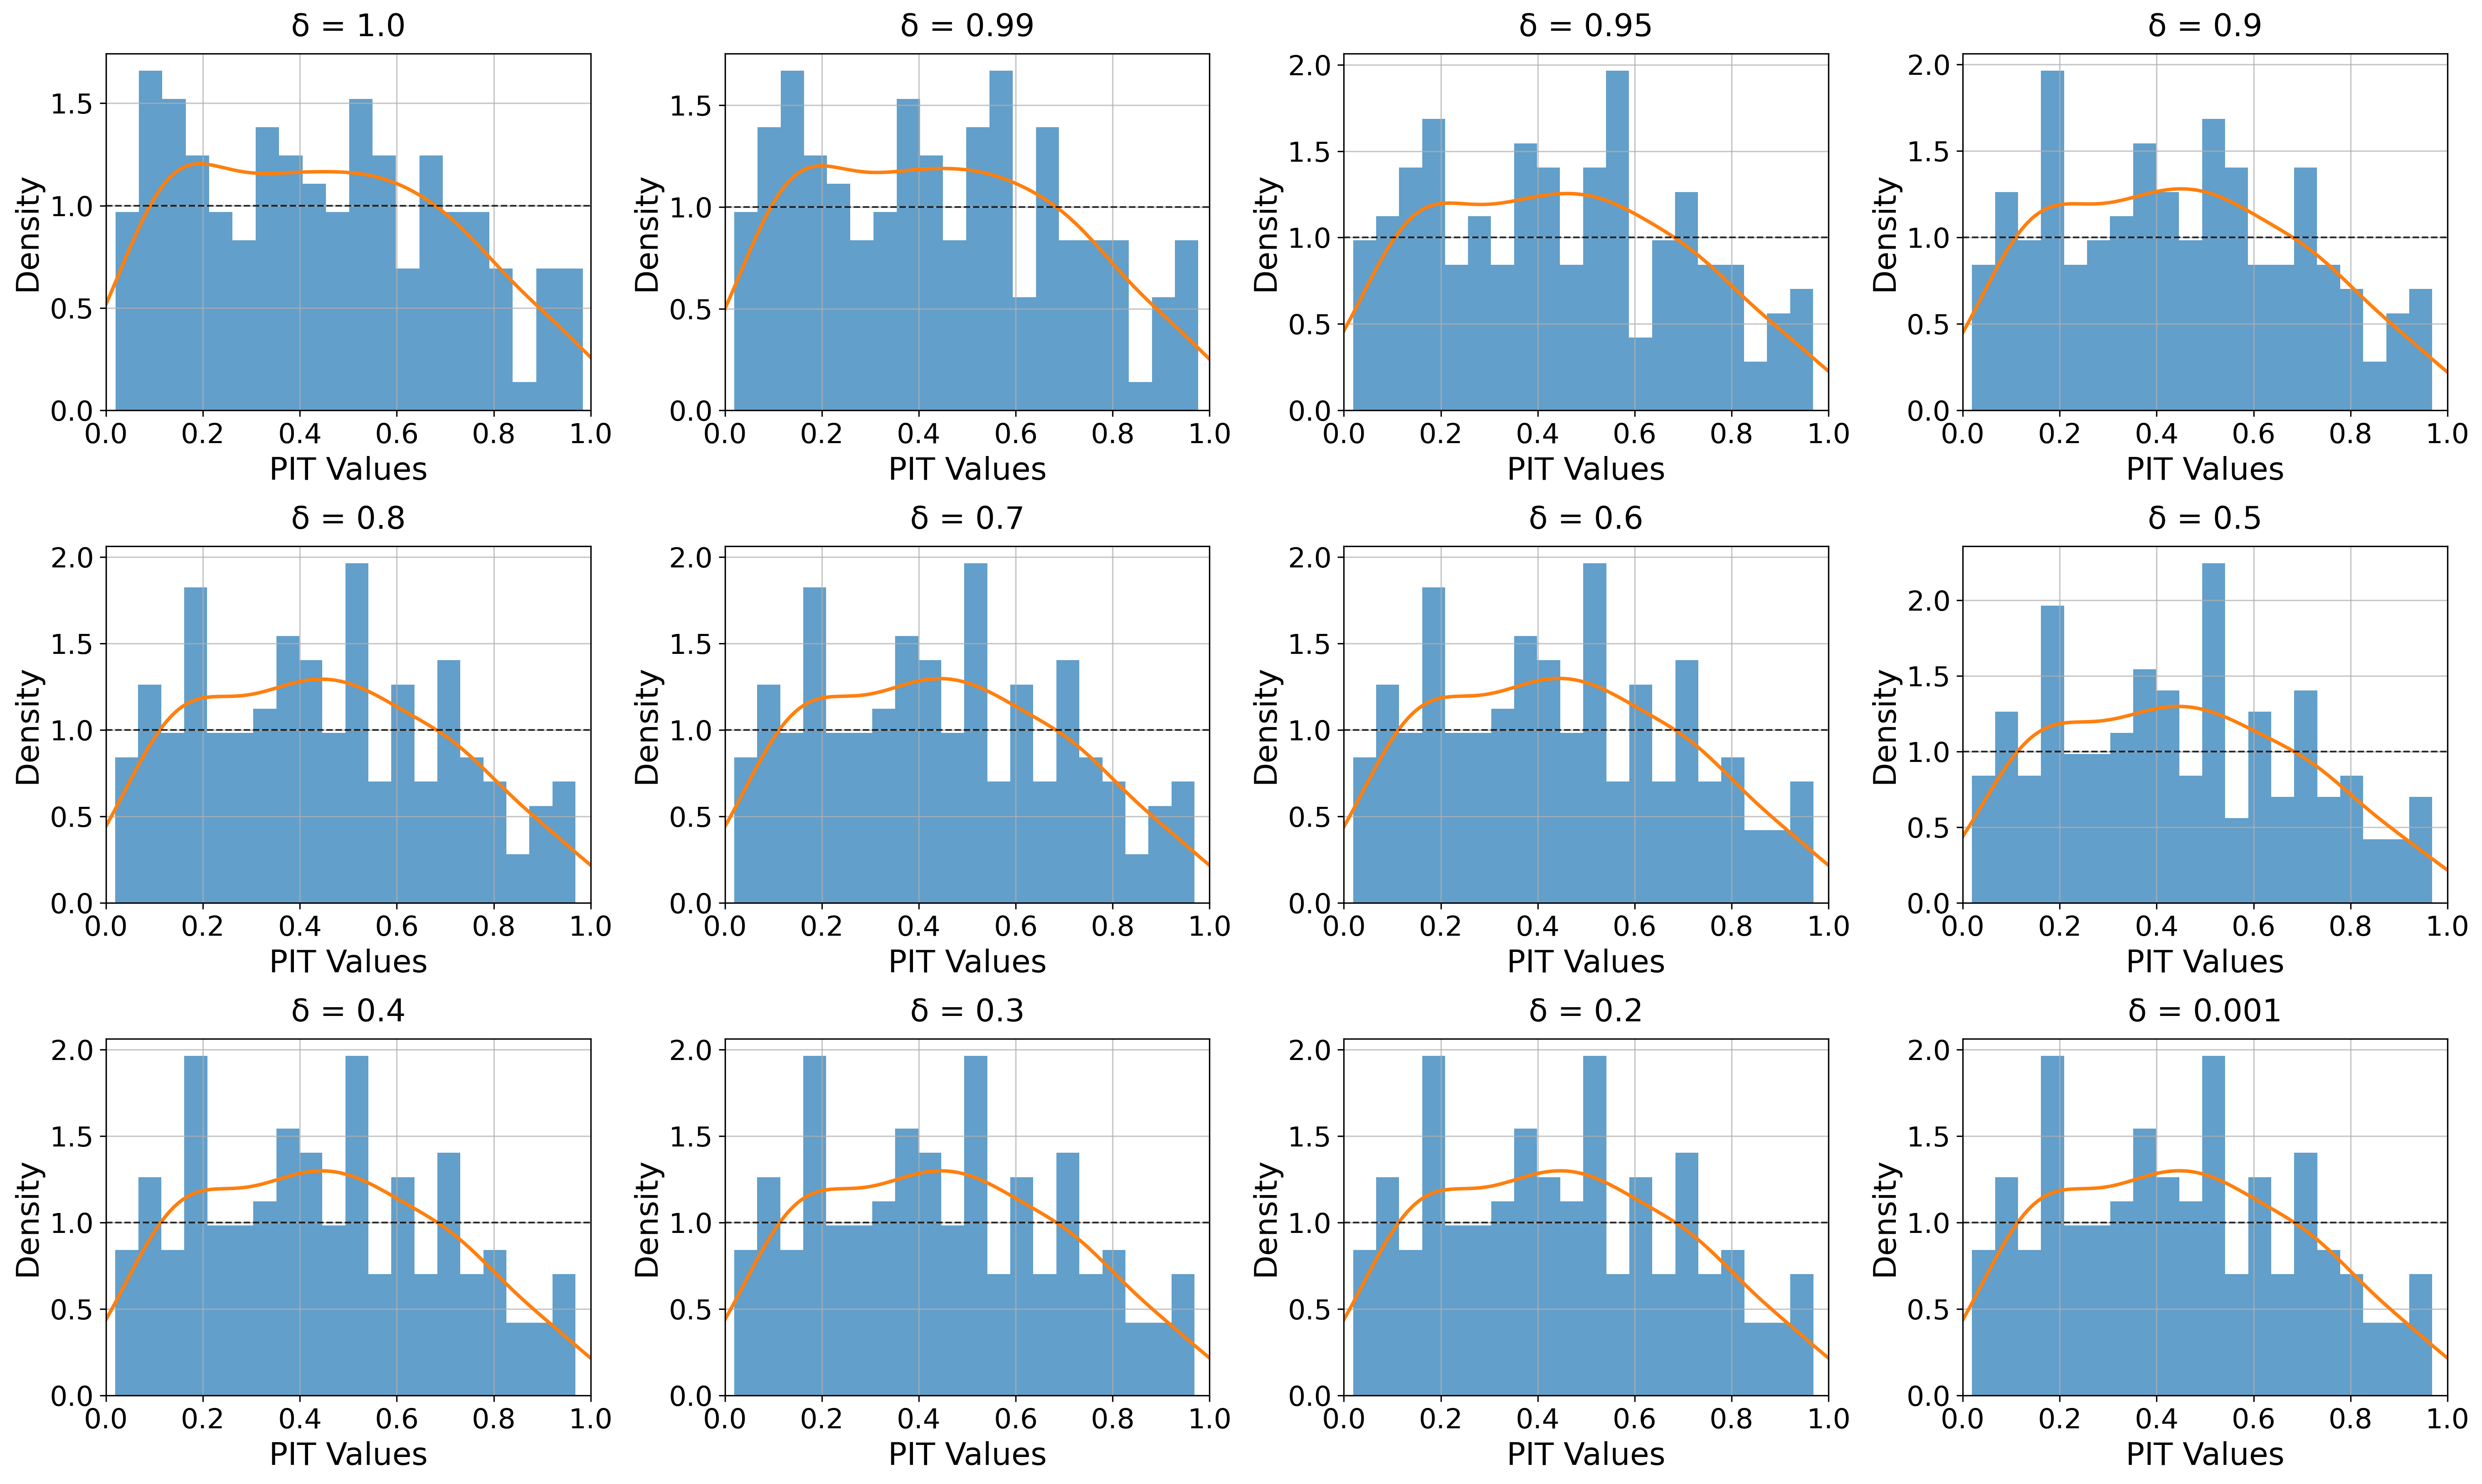

In [43]:
plot_pit_histograms(pit_values,discount_factors,show_smooth=True)

In [44]:
result_df,original_df = uniformity_test(pit_values,discount_factors)
original_df

,Model,Tests_Passed,KS_Test,AD_Test,Chi2_Test,DH_Test,LB_Test,Berkowitz_Test,Mean_Test,Variance_Test,Coverage_5%_Test,Coverage_95%_Test,Efficiency_Test,Probabilistic_Calibration,Complete_Calibration
0,δ = 1.0,3/10,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL,PASS,PASS,N/A,Rejected,Rejected
1,δ = 0.99,3/10,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL,PASS,PASS,N/A,Rejected,Rejected
2,δ = 0.95,2/10,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,N/A,Rejected,Rejected
3,δ = 0.9,2/10,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,N/A,Rejected,Rejected
4,δ = 0.8,2/10,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,N/A,Rejected,Rejected
5,δ = 0.7,3/10,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL,PASS,PASS,N/A,Rejected,Rejected
6,δ = 0.6,3/10,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL,PASS,PASS,N/A,Rejected,Rejected
7,δ = 0.5,3/10,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL,PASS,PASS,N/A,Rejected,Rejected
8,δ = 0.4,3/10,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL,PASS,PASS,N/A,Rejected,Rejected
9,δ = 0.3,3/10,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL,PASS,PASS,N/A,Rejected,Rejected


In [46]:
def compute_pdf(mean, vol, dof, x_grid,weights):

    models = ['M1', 'M2', 'M3', 'M4']
    T = len(mean)
    M = len(x_grid)
    K = len(models)
    
    cdfs = np.zeros((K, T, M))
    
    for k, model in enumerate(models):
        for t in range(T):
            # CDF at all grid points
            cdfs[k, t, :] = stats.t.pdf(
                x_grid,
                loc=mean[model].to_numpy()[t],
                scale=np.sqrt(vol[model].to_numpy()[t]),
                df=dof[model].to_numpy()[t]
            )

    pdfs = np.einsum('ktm,ptk -> ptm', cdfs, weights)
    
    return pdfs

pdfs = compute_pdf(mean, vol, dof, x_grid ,res_ldf["weights"])
ex_log_pdf = np.log(pit_func(pdfs, x_grid, y))

## Recalibration settings — one configuration for every method (M4)

Every method and benchmark below uses these values. `EVAL_START = WARMUP + MIN_TRAIN` is the first period at which the composition's network is active, so all methods are scored on the **same window** where all of them are fully running. `STEP_NORM='global'` reproduces the original filter; `'coord'` gives each map parameter the same step size, so the Beta-vs-spline comparison is not a step-size comparison.

In [47]:
from recal_dma_new import (tvgas_pit_dma_new, convolution_recal_pit_dma_new, run_static_expanding,
                           check_comparability, _print_report, FEATURE_NAMES, _prep_pit)
from recal_beta_dma_new import (tvgas_pit_beta_dma_new, convolution_recal_pit_beta_dma_new,
                                run_static_expanding_beta)

K            = 4          # spline bins, SAME for GAS and composition (previously 3 vs 4)
WARMUP       = 0
EVAL_START   = WARMUP
ALPHA, FLOOR = 0.98, 1e-3 # DMA forgetting and weight floor, all methods
STEP_NORM    = 'coord'    # 'global' = original filter
SLOW_SHRINK  = 1.0        # 1.0 = random-walk slow component (original)
REFIT, HIDDEN, EPOCHS, LR, SEED = 10, 4, 300, 1e-3, 42
STATIC_REFIT = REFIT        # static baselines refitted as often as the network
ROLL_WINDOWS = (40, 80)   # rolling-window static baselines

discount_factors = np.asarray(discount_factors, float)
D_MAIN = int(np.argmin(np.abs(discount_factors - 0.9)))   # main specification; the rest = robustness
T = pit_values.shape[1]
assert T == len(y), "PITs and outcomes must cover the same periods"
y_arr = np.asarray(y, float)
SL = slice(EVAL_START, T)
print(f"T = {T}, evaluation window [{EVAL_START}, {T}) = {T - EVAL_START} quarters, main delta = {discount_factors[D_MAIN]}")

T = 150, evaluation window [0, 150) = 150 quarters, main delta = 0.9


## Run the four recalibration methods

Both GAS functions also fit the **static expanding-window map** of eq. (9) for their family (`static_baseline=True`) and report a HAC DM test of GAS against it (`dm_vs_static`). Both composition functions report a HAC DM test against GAS alone (`dm_vs_gas_only`).

In [48]:
common = dict(x=x_grid, y=y, pit_data=pit_values, cdf_data=cdfs, discount_factors=discount_factors,
              warmup=WARMUP, eval_start=EVAL_START, alpha=ALPHA, floor=FLOOR)
net = dict(refit_every=REFIT, hidden_size=HIDDEN, num_epochs=EPOCHS, learning_rate=LR, seed=SEED)

rg_dma = tvgas_pit_dma_new(K=K, **common, static_baseline=True, static_refit_every=STATIC_REFIT, verbose=False)
rc_dma = convolution_recal_pit_dma_new(K=K, **common, **net, verbose=False)
bg_dma = tvgas_pit_beta_dma_new(**common, static_baseline=True, static_refit_every=STATIC_REFIT, verbose=False)
bc_dma = convolution_recal_pit_beta_dma_new(**common, **net, verbose=False)
METHODS = {'RQS-GAS': rg_dma, 'RQS-Con': rc_dma, 'Beta-GAS': bg_dma, 'Beta-Con': bc_dma}

In [49]:
# full console report for the main specification only
for name, res in METHODS.items():
    print(f"\n----- {name}  (delta = {discount_factors[D_MAIN]}) -----")
    _print_report(f"EVALUATION [{EVAL_START},{T})", res[D_MAIN])

# the raw-pool baselines must be identical across methods before anything is tabulated
check_comparability(rg_dma[D_MAIN], bc_dma[D_MAIN], labels=('RQS-GAS', 'Beta-Con'))


----- RQS-GAS  (delta = 0.9) -----
  EVALUATION [0,150)  n=150
     log-score total    +1.970   per obs +0.0131 (SE 0.0206)   t=+0.61  p=0.540
     oracle ceiling +0.0617/obs  -> captured 21%
     KS   0.1323 -> 0.0613   (null mean 0.0709)
     ECE  0.2933 -> 0.2133   CRPS 0.1586 -> 0.1571
     mean bias +0.0572 -> +0.0223
     PIT var by third  0.0505 0.0457 0.0891  ->  0.0618 0.0695 0.0924   (target 0.0833)

----- RQS-Con  (delta = 0.9) -----
  EVALUATION [0,150)  n=150
     log-score total    +1.843   per obs +0.0123 (SE 0.0247)   t=+0.49  p=0.626
     oracle ceiling +0.0617/obs  -> captured 20%
     KS   0.1323 -> 0.0619   (null mean 0.0709)
     ECE  0.2933 -> 0.1867   CRPS 0.1586 -> 0.1566
     mean bias +0.0572 -> +0.0224
     PIT var by third  0.0505 0.0457 0.0891  ->  0.0619 0.0762 0.0928   (target 0.0833)

----- Beta-GAS  (delta = 0.9) -----
  EVALUATION [0,150)  n=150
     log-score total    +3.840   per obs +0.0256 (SE 0.0157)   t=+1.53  p=0.127
     oracle ceiling +0.0617

True

## Benchmarks 

In [50]:
BENCH = {'Static-RQS (exp)': [], 'Static-Beta (exp)': []}
for w in ROLL_WINDOWS:
    BENCH[f'Static-RQS (roll {w})'] = []
    BENCH[f'Static-Beta (roll {w})'] = []

for i in range(len(discount_factors)):
    u = _prep_pit(pit_values[i])
    BENCH['Static-RQS (exp)'].append(dict(kind='rqs', ll=rg_dma[i]['ll_static'],
                                          v=rg_dma[i]['v_static'], path=rg_dma[i]['theta_static']))
    BENCH['Static-Beta (exp)'].append(dict(kind='beta', ll=bg_dma[i]['ll_static'],
                                           v=bg_dma[i]['v_static'], path=bg_dma[i]['logits_static']))
    for w in ROLL_WINDOWS:
        ll, path, v = run_static_expanding(u, K, WARMUP, refit_every=STATIC_REFIT, window=w)
        BENCH[f'Static-RQS (roll {w})'].append(dict(kind='rqs', ll=ll, v=v, path=path))
        ll, path, v = run_static_expanding_beta(u, WARMUP, refit_every=STATIC_REFIT, window=w)
        BENCH[f'Static-Beta (roll {w})'].append(dict(kind='beta', ll=ll, v=v, path=path))

In [53]:
# CRPS and 90% intervals for the benchmarks, through the SAME quadrature as the methods
from recal_dma_new import _spline_on_grid, _pit_moments, _pit_quantiles, _UN, _IVL_PROBS
from recal_beta_dma_new import _bank_eval_beta

def score_static(entry, i):
    crps = np.zeros(T); q = np.zeros((T, 2))
    for t in range(T):
        if entry['kind'] == 'rqs':
            tau, dtau = _spline_on_grid(entry['path'][t], K)
        else:
            tau, dtau = _bank_eval_beta(entry['path'][t][None, :], _UN, np.array([1.0]))
        _, crps[t] = _pit_moments(cdfs[i][t], x_grid, y_arr[t], tau, dtau)
        q[t] = _pit_quantiles(cdfs[i][t], x_grid, tau, _IVL_PROBS)
    entry['crps'], entry['q'] = crps, q

for name in BENCH:
    score_static(BENCH[name][D_MAIN], D_MAIN)

## Ablations of the composition (M5), main specification

* **network only** — inner map alone, no filter bank (`outer='none'`)
* **linear head** — `hidden_size=0`
* **no median_loc** — drops the location feature, to check the gain is shape-driven rather than a location-keyed bias correction

In [54]:
one = dict(common, pit_data=pit_values[D_MAIN:D_MAIN + 1], cdf_data=cdfs[D_MAIN:D_MAIN + 1],
           discount_factors=discount_factors[D_MAIN:D_MAIN + 1])
no_loc = [f for f in FEATURE_NAMES if f != 'median_loc']
ABL = {}
for lab, extra in [('network only', dict(outer='none')),
                   ('linear head', dict(hidden_size=0)),
                   ('no median_loc', dict(features=no_loc))]:
    ABL[f'RQS-Con: {lab}'] = convolution_recal_pit_dma_new(K=K, **one, **{**net, **extra}, verbose=False)[0]
    ABL[f'Beta-Con: {lab}'] = convolution_recal_pit_beta_dma_new(**one, **{**net, **extra}, verbose=False)[0]

## Main results, $\delta = 0.9$ (M6)

Every row is computed by the same code from per-period log scores, PITs, CRPS and interval quantiles, on `[EVAL_START, T)`.

* **ΔLogS** mean log-score gain over the raw pool, with HAC DM *t* (Giacomini–White, Newey–West lags $\lfloor 4(n/100)^{2/9}\rfloor$). Negative *t* = significantly **worse** than raw.
* **ΔCRPS %**, **ΔIS90 %**: reduction relative to raw (positive = better), with DM *t*.
* **Width** (sharpness) and **coverage** of the 90% interval. Width < raw means sharper.
* **KS** of the recalibrated PITs; **Moment p**: raw-moment calibration test with HAC covariance (in the spirit of Knüppel 2015), robust to serial dependence, unlike KS/AD.
* **t vs static**: DM against the expanding static map of the same family (the time-variation test). **t vs GAS**: composition against GAS of the same family.

In [55]:
from recal_dma_new import dm_test, _hac_lag, _interval_metrics

def dm_t(d):
    d = np.asarray(d, float)
    return dm_test(d, hac_lag=_hac_lag(len(d)))[2]

def raw_moment_test(v, n_mom=4):
    # H0: E[v^k] = 1/(k+1), k = 1..n_mom (uniform PIT), HAC covariance -> chi2(n_mom)
    v = np.asarray(v, float)
    m = np.column_stack([v ** k - 1.0 / (k + 1) for k in range(1, n_mom + 1)])
    n = len(v); mbar = m.mean(0); e = m - mbar; L = _hac_lag(n)
    S = e.T @ e / n
    for l in range(1, L + 1):
        G = e[l:].T @ e[:-l] / n
        S += (1 - l / (L + 1)) * (G + G.T)
    stat = float(n * mbar @ np.linalg.solve(S, mbar))
    return stat, float(1 - stats.chi2.cdf(stat, n_mom))

ref = rg_dma[D_MAIN]
crps_raw = ref['crps_raw_history']
q_raw = np.column_stack([ref['y_raw_q05'], ref['y_raw_q95']])
u_main = _prep_pit(pit_values[D_MAIN])

def row(ll, v_eval, crps, q, ll_static=None, ll_gas=None):
    # ll, crps, q: full-length (T); v_eval: recalibrated PITs on the window
    ivl, ivl_raw = _interval_metrics(q, y_arr, SL), _interval_metrics(q_raw, y_arr, SL)
    return {
        'ΔLogS': ll[SL].mean(), 't LogS': dm_t(ll[SL]),
        'ΔCRPS %': 100 * (1 - crps[SL].mean() / crps_raw[SL].mean()),
        't CRPS': dm_t(crps_raw[SL] - crps[SL]),
        'ΔIS90 %': 100 * (1 - ivl['score'] / ivl_raw['score']),
        't IS90': dm_t(ivl_raw['per_obs_score'] - ivl['per_obs_score']),
        'Width': ivl['width'], 'Coverage': ivl['coverage'],
        'KS': stats.kstest(v_eval, 'uniform').statistic,
        'Moment p': raw_moment_test(v_eval)[1],
        't vs static': dm_t(ll[SL] - ll_static[SL]) if ll_static is not None else np.nan,
        't vs GAS': dm_t(ll[SL] - ll_gas[SL]) if ll_gas is not None else np.nan}

def res_q(r):
    return np.column_stack([r['y_calibrated_q05'], r['y_calibrated_q95']])

rows = {'Raw pool': row(np.zeros(T), u_main[SL], crps_raw, q_raw)}
for name, b in BENCH.items():
    e = b[D_MAIN]
    rows[name] = row(e['ll'], e['v'][SL], e['crps'], e['q'])
st_rqs, st_beta = BENCH['Static-RQS (exp)'][D_MAIN]['ll'], BENCH['Static-Beta (exp)'][D_MAIN]['ll']
for name, r in METHODS.items():
    r = r[D_MAIN]
    st = st_rqs if name.startswith('RQS') else st_beta
    gas = (rg_dma if name.startswith('RQS') else bg_dma)[D_MAIN]['log_likelihood'] if name.endswith('Con') else None
    rows[name] = row(r['log_likelihood'], r['calibrated_pits'], r['crps_history'], res_q(r),
                     ll_static=st, ll_gas=gas)
for name, r in ABL.items():
    gas = (rg_dma if name.startswith('RQS') else bg_dma)[D_MAIN]['log_likelihood']
    rows[name] = row(r['log_likelihood'], r['calibrated_pits'], r['crps_history'], res_q(r), ll_gas=gas)

main_table = pd.DataFrame(rows).T
main_table.style.format({'ΔLogS': '{:+.4f}', 'ΔCRPS %': '{:+.2f}', 'ΔIS90 %': '{:+.2f}',
                         'Width': '{:.3f}', 'Coverage': '{:.3f}', 'KS': '{:.3f}', 'Moment p': '{:.3f}',
                         **{c: '{:+.2f}' for c in main_table.columns if c.startswith('t')}})

,ΔLogS,t LogS,ΔCRPS %,t CRPS,ΔIS90 %,t IS90,Width,Coverage,KS,Moment p,t vs static,t vs GAS
Raw pool,+0.0000,+0.00,+0.00,+0.00,+0.00,+0.00,1.188,0.967,0.132,0.000,+nan,+nan
Static-RQS (exp),-0.0448,-1.15,+1.72,+1.09,+1.32,+0.30,0.976,0.893,0.056,0.743,+nan,+nan
Static-Beta (exp),+0.0324,+0.94,+2.05,+1.36,+1.03,+0.22,0.963,0.893,0.051,0.928,+nan,+nan
Static-RQS (roll 40),-0.0636,-1.17,+1.14,+0.68,+3.41,+1.07,1.017,0.900,0.055,0.870,+nan,+nan
Static-Beta (roll 40),+0.0344,+1.01,+1.91,+1.31,+2.82,+0.80,1.013,0.907,0.046,0.939,+nan,+nan
Static-RQS (roll 80),-0.0672,-1.59,+1.45,+0.89,+1.38,+0.34,0.992,0.893,0.047,0.818,+nan,+nan
Static-Beta (roll 80),+0.0305,+0.88,+1.97,+1.30,+0.86,+0.19,0.976,0.893,0.050,0.942,+nan,+nan
RQS-GAS,+0.0131,+0.61,+0.97,+0.87,+2.09,+2.03,1.139,0.940,0.061,0.018,+1.91,+nan
RQS-Con,+0.0123,+0.49,+1.29,+1.13,+2.66,+2.61,1.123,0.933,0.062,0.054,+1.77,-0.10
Beta-GAS,+0.0256,+1.53,+0.15,+0.13,+4.57,+2.14,1.065,0.927,0.064,0.540,-0.31,+nan


In [56]:
def stars(t):
    a = abs(t)
    return '' if not np.isfinite(t) else '***' if a > 2.576 else '**' if a > 1.960 else '*' if a > 1.645 else ''

def main_table_latex(tab, caption, label):
    cols = [('ΔLogS', 't LogS', '{:+.4f}'), ('ΔCRPS %', 't CRPS', '{:+.2f}'), ('ΔIS90 %', 't IS90', '{:+.2f}')]
    head = r"Method & $\Delta$LogS & $\Delta$CRPS\,\% & $\Delta$IS$_{90}$\,\% & Width & Cov. & KS & Moment $p$ \\"
    lines = [r"\begin{table}[H]", r"\centering", r"\small", r"\begin{tabular}{l rrr rr rr}", r"\toprule", head, r"\midrule"]
    for name, r in tab.iterrows():
        cells_ = [fmt.format(r[c]) + (f"$^{{{stars(r[tc])}}}$" if stars(r[tc]) else '') for c, tc, fmt in cols]
        cells_ += [f"{r['Width']:.3f}", f"{r['Coverage']:.2f}", f"{r['KS']:.3f}", f"{r['Moment p']:.2f}"]
        lines.append(f"{name} & " + " & ".join(cells_) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", rf"\caption{{{caption}}}", rf"\label{{{label}}}", r"\end{table}"]
    print("\n".join(lines))

main_table_latex(main_table.drop(index=list(ABL)),
                 caption=(r"US inflation, $\delta=0.9$: gains over the raw LDF$^2_{s,s}$ pool on the common "
                          r"evaluation window. Stars: HAC DM test, 10/5/1\%. Positive = better than raw."),
                 label="tab:inflation-main")

\begin{table}[H]
\centering
\small
\begin{tabular}{l rrr rr rr}
\toprule
Method & $\Delta$LogS & $\Delta$CRPS\,\% & $\Delta$IS$_{90}$\,\% & Width & Cov. & KS & Moment $p$ \\
\midrule
Raw pool & +0.0000 & +0.00 & +0.00 & 1.188 & 0.97 & 0.132 & 0.00 \\
Static-RQS (exp) & -0.0448 & +1.72 & +1.32 & 0.976 & 0.89 & 0.056 & 0.74 \\
Static-Beta (exp) & +0.0324 & +2.05 & +1.03 & 0.963 & 0.89 & 0.051 & 0.93 \\
Static-RQS (roll 40) & -0.0636 & +1.14 & +3.41 & 1.017 & 0.90 & 0.055 & 0.87 \\
Static-Beta (roll 40) & +0.0344 & +1.91 & +2.82 & 1.013 & 0.91 & 0.046 & 0.94 \\
Static-RQS (roll 80) & -0.0672 & +1.45 & +1.38 & 0.992 & 0.89 & 0.047 & 0.82 \\
Static-Beta (roll 80) & +0.0305 & +1.97 & +0.86 & 0.976 & 0.89 & 0.050 & 0.94 \\
RQS-GAS & +0.0131 & +0.97 & +2.09$^{**}$ & 1.139 & 0.94 & 0.061 & 0.02 \\
RQS-Con & +0.0123 & +1.29 & +2.66$^{***}$ & 1.123 & 0.93 & 0.062 & 0.05 \\
Beta-GAS & +0.0256 & +0.15 & +4.57$^{**}$ & 1.065 & 0.93 & 0.064 & 0.54 \\
Beta-Con & +0.0287 & +0.86 & +4.65 & 1.028 & 0.92 

## Robustness across the 12 LDF discount factors

Mean log-score gain per method and benchmark, with HAC DM stars, plus the GAS-vs-static and Con-vs-GAS tests. The last rows count the discount factors at which each comparison is **significantly positive** and **significantly negative** at 5%. These configurations share data, so the counts are descriptive, not independent tests.

In [57]:
def gain_star(ll):
    d = ll[SL]
    return f"{d.mean():+.4f}{stars(dm_t(d))}"

rob = {}
for i, dfac in enumerate(discount_factors):
    r = {}
    for name, b in BENCH.items():
        r[name] = gain_star(b[i]['ll'])
    for name, res in METHODS.items():
        r[name] = gain_star(res[i]['log_likelihood'])
    r['t RQS-GAS vs static'] = dm_t(rg_dma[i]['log_likelihood'][SL] - rg_dma[i]['ll_static'][SL])
    r['t Beta-GAS vs static'] = dm_t(bg_dma[i]['log_likelihood'][SL] - bg_dma[i]['ll_static'][SL])
    r['t RQS-Con vs GAS'] = rc_dma[i]['dm_vs_gas_only']['t']
    r['t Beta-Con vs GAS'] = bc_dma[i]['dm_vs_gas_only']['t']
    rob[dfac] = r
rob_table = pd.DataFrame(rob).T
rob_table.index.name = 'delta'

tcols = [c for c in rob_table.columns if c.startswith('t ')]
counts = pd.DataFrame({c: {'# sig. better (5%)': int((rob_table[c].astype(float) > 1.96).sum()),
                           '# sig. worse (5%)': int((rob_table[c].astype(float) < -1.96).sum())}
                       for c in tcols})
display(rob_table.style.format({c: '{:+.2f}' for c in tcols}))
display(counts)

,Static-RQS (exp),Static-Beta (exp),Static-RQS (roll 40),Static-Beta (roll 40),Static-RQS (roll 80),Static-Beta (roll 80),RQS-GAS,RQS-Con,Beta-GAS,Beta-Con,t RQS-GAS vs static,t Beta-GAS vs static,t RQS-Con vs GAS,t Beta-Con vs GAS
delta,,,,,,,,,,,,,,
1.000000,-0.0287,+0.0128,-0.0834,+0.0199,-0.0539,+0.0141,+0.0104,+0.0167,+0.0162,+0.0303,+1.65,+0.16,+1.04,+0.83
0.990000,-0.0117,+0.0180,-0.0563,+0.0223,-0.0398,+0.0182,+0.0120,+0.0136,+0.0178,+0.0320,+0.97,-0.01,+0.25,+1.07
0.950000,-0.0057,+0.0300,-0.0473,+0.0313,-0.0268,+0.0285,+0.0119,+0.0089,+0.0234,+0.0340,+0.63,-0.32,-0.41,+0.55
0.900000,-0.0448,+0.0324,-0.0636,+0.0344,-0.0672,+0.0305,+0.0131,+0.0123,+0.0256,+0.0287,+1.91,-0.31,-0.10,+0.18
0.800000,-0.0354,+0.0333,-0.0529,+0.0361,-0.0626,+0.0313,+0.0149,+0.0195,+0.0270,+0.0289,+1.48,-0.28,+0.31,+0.12
0.700000,-0.0035,+0.0335,-0.0157,+0.0367,-0.0209,+0.0315,+0.0146,+0.0167,+0.0276,+0.0418,+0.57,-0.27,+0.20,+0.85
0.600000,-0.0035,+0.0336,-0.0162,+0.0369,-0.0191,+0.0315,+0.0147,+0.0184,+0.0278,+0.0350,+0.54,-0.26,+0.32,+0.46
0.500000,-0.0043,+0.0336,-0.0178,+0.0370,-0.0213,+0.0316,+0.0145,+0.0206,+0.0280,+0.0423,+0.58,-0.25,+0.64,+0.89
0.400000,-0.0238,+0.0336,-0.0724,+0.0371,-0.0402,+0.0316,+0.0149,+0.0218,+0.0281,+0.0460,+1.11,-0.24,+0.65,+1.03


,t RQS-GAS vs static,t Beta-GAS vs static,t RQS-Con vs GAS,t Beta-Con vs GAS
# sig. better (5%),0,0,0,0
# sig. worse (5%),0,0,0,0


## Calibration tests on the evaluation window

The raw pool is now tested on the same window as the recalibrated forecasts (previously the full sample). Note that KS, AD and $\chi^2$ assume independent PITs; where Ljung–Box rejects, read them alongside the dependence-robust *Moment p* above.

In [76]:
def stack_pits(res_list):
    return np.vstack([r['calibrated_pits'] for r in res_list])

raw_eval = np.vstack([_prep_pit(pit_values[i])[SL] for i in range(len(discount_factors))])
rc_calibrated_pits, rg_calibrated_pits = stack_pits(rc_dma), stack_pits(rg_dma)
bc_calibrated_pits, bg_calibrated_pits = stack_pits(bc_dma), stack_pits(bg_dma)

TESTS = {}
_, TESTS['Raw pool'] = uniformity_test(raw_eval, discount_factors)
for name, b in [('Static-RQS (exp)', BENCH['Static-RQS (exp)']), ('Static-Beta (exp)', BENCH['Static-Beta (exp)'])]:
    _, TESTS[name] = uniformity_test(np.vstack([e['v'][SL] for e in b]), discount_factors)
_, TESTS['RQS-GAS'] = uniformity_test(rg_calibrated_pits, discount_factors)
_, TESTS['RQS-Con'] = uniformity_test(rc_calibrated_pits, discount_factors)
_, TESTS['Beta-GAS'] = uniformity_test(bg_calibrated_pits, discount_factors)
_, TESTS['Beta-Con'] = uniformity_test(bc_calibrated_pits, discount_factors)
TESTS['Static-RQS (exp)']

,Model,Tests_Passed,KS_Test,AD_Test,Chi2_Test,DH_Test,LB_Test,Berkowitz_Test,Mean_Test,Variance_Test,Coverage_5%_Test,Coverage_95%_Test,Efficiency_Test,Probabilistic_Calibration,Complete_Calibration
0,δ = 1.0,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
1,δ = 0.99,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
2,δ = 0.95,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
3,δ = 0.9,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
4,δ = 0.8,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
5,δ = 0.7,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
6,δ = 0.6,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
7,δ = 0.5,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
8,δ = 0.4,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected
9,δ = 0.3,9/10,PASS,PASS,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,N/A,Not rejected,Rejected


In [59]:
def tests_passed_latex(tables, caption="Number of tests passed for each method",
                       label="tab:tests-passed"):
    # tables: {row label: test-result DataFrame}; counts the discount factors marked PASS per test
    cols = [("KS_Test", "KS"), ("AD_Test", "AD"), ("Chi2_Test", r"$\chi^2$"),
            ("DH_Test", "DH"), ("LB_Test", "LB"), ("Berkowitz_Test", "Berkowitz")]
    lines = [r"\begin{table}[H]", r"\centering", r"\onehalfspacing", r"\small",
             r"\begin{tabular}{l " + "c " * len(cols) + "}", r"\toprule",
             " & " + " & ".join(h for _, h in cols) + r" \\", r"\midrule"]
    for name, df in tables.items():
        counts = [int(df[c].astype(str).str.strip().str.upper().eq("PASS").sum()) for c, _ in cols]
        lines.append(f"{name} & " + " & ".join(map(str, counts)) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", rf"\caption{{{caption}}}",
              rf"\label{{{label}}}", r"\end{table}"]
    print("\n".join(lines))

tests_passed_latex(TESTS, caption=(f"US inflation: number of the {len(discount_factors)} LDF discount factors at which "
                                   f"each test does not reject at 5\\%, evaluation window [{EVAL_START}, {T})."))

\begin{table}[H]
\centering
\onehalfspacing
\small
\begin{tabular}{l c c c c c c }
\toprule
 & KS & AD & $\chi^2$ & DH & LB & Berkowitz \\
\midrule
Raw pool & 0 & 0 & 0 & 12 & 0 & 0 \\
Static-RQS (exp) & 12 & 12 & 12 & 12 & 0 & 12 \\
Static-Beta (exp) & 12 & 12 & 12 & 12 & 0 & 12 \\
RQS-GAS & 12 & 12 & 12 & 12 & 0 & 12 \\
RQS-Con & 12 & 12 & 12 & 12 & 0 & 12 \\
Beta-GAS & 12 & 12 & 12 & 12 & 0 & 12 \\
Beta-Con & 12 & 12 & 12 & 12 & 0 & 12 \\
\bottomrule
\end{tabular}
\caption{US inflation: number of the 12 LDF discount factors at which each test does not reject at 5\%, evaluation window [0, 150).}
\label{tab:tests-passed}
\end{table}


## Figures (main specification)

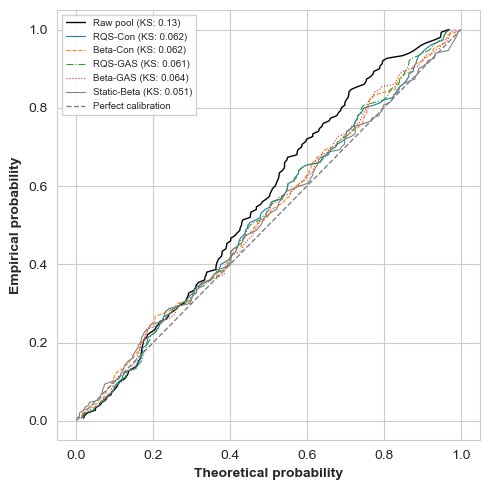

In [60]:
index = D_MAIN
pit_example = _prep_pit(pit_values[index])[SL]
n = len(pit_example)
ecdf = np.arange(1, n + 1) / n

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(np.sort(pit_example), ecdf, color='black', lw=1,
        label=f"Raw pool (KS: {rc_dma[index]['ks_before']:.2g})")
for lab, res, col, ls in [('RQS-Con', rc_dma, '#1f77b4', '-'), ('Beta-Con', bc_dma, '#ff7f0e', '--'),
                          ('RQS-GAS', rg_dma, '#2ca02c', '-.'), ('Beta-GAS', bg_dma, '#d62728', ':')]:
    ax.plot(np.sort(res[index]['calibrated_pits']), ecdf, color=col, linestyle=ls, lw=0.8,
            label=f"{lab} (KS: {res[index]['ks_after']:.2g})")
vs = BENCH['Static-Beta (exp)'][index]['v'][SL]
ax.plot(np.sort(vs), ecdf, color='grey', lw=0.8, label=f"Static-Beta (KS: {stats.kstest(vs, 'uniform').statistic:.2g})")
ax.plot([0, 1], [0, 1], color='grey', linestyle='--', lw=1, label='Perfect calibration')
ax.set_xlabel('Theoretical probability', fontsize=10, fontweight='bold')
ax.set_ylabel('Empirical probability', fontsize=10, fontweight='bold')
ax.legend(fontsize=7, loc='upper left', frameon=True, framealpha=0.9, edgecolor='0.8', fancybox=False)
plt.tight_layout()
plt.show()

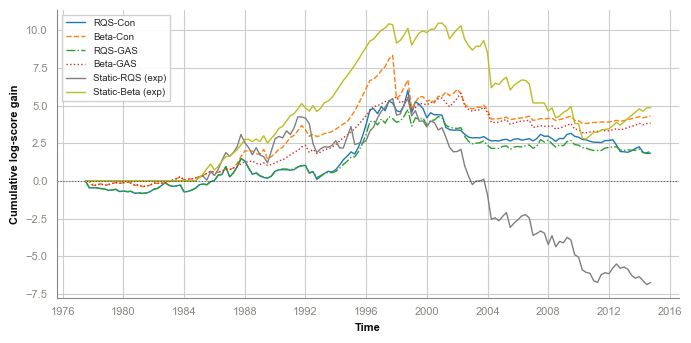

In [78]:
# cumulative log-score gain over the raw pool, methods and static benchmarks
dates = pd.to_datetime(y_t["Date"])
fig, ax = plt.subplots(figsize=(7, 3.5))
for lab, ll, col, ls in [('RQS-Con', rc_dma[index]['log_likelihood'], '#1f77b4', '-'),
                         ('Beta-Con', bc_dma[index]['log_likelihood'], '#ff7f0e', '--'),
                         ('RQS-GAS', rg_dma[index]['log_likelihood'], '#2ca02c', '-.'),
                         ('Beta-GAS', bg_dma[index]['log_likelihood'], '#d62728', ':'),
                         ('Static-RQS (exp)', BENCH['Static-RQS (exp)'][index]['ll'], '#7f7f7f', '-'),
                         ('Static-Beta (exp)', BENCH['Static-Beta (exp)'][index]['ll'], '#bcbd22', '-')]:
    ax.plot(dates[SL], np.cumsum(ll[SL]), label=lab, color=col, linestyle=ls, linewidth=1)
ax.axhline(0, color='black', linestyle=':', linewidth=0.8, alpha=0.5)
ax.set_xlabel('Time', fontsize=8, fontweight='bold')
ax.set_ylabel('Cumulative log-score gain', fontsize=8, fontweight='bold')
ax.tick_params(axis='both', labelsize=8)
ax.legend(fontsize=7, loc='upper left', frameon=True, framealpha=0.9, edgecolor='0.8', fancybox=False)
sns.despine()
plt.tight_layout()
plt.show()

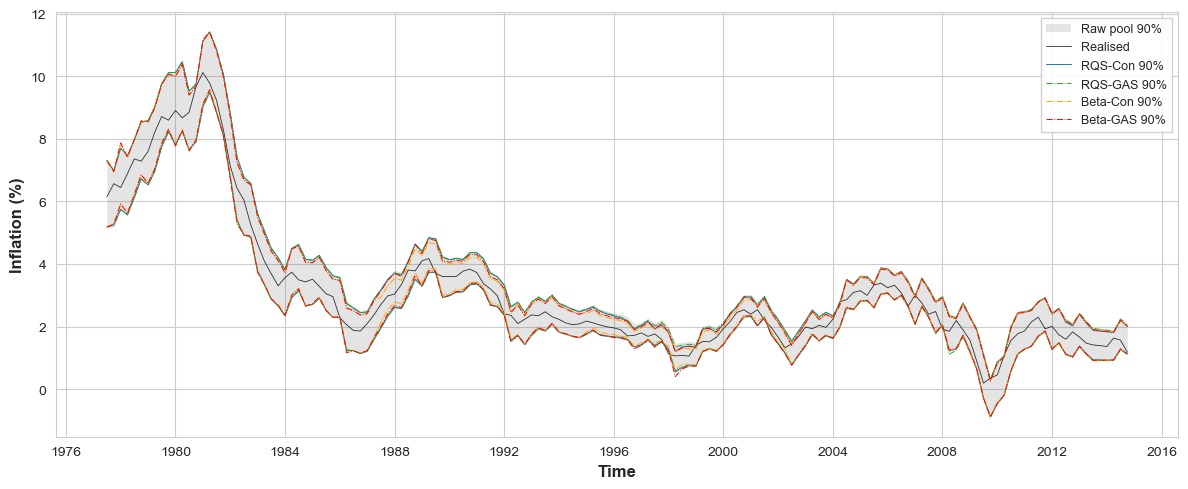

                       Coverage  Width  Width / raw
Raw pool                  0.967  1.188        1.000
Static-RQS (exp)          0.893  0.976        0.822
Static-Beta (exp)         0.893  0.963        0.811
Static-RQS (roll 40)      0.900  1.017        0.856
Static-Beta (roll 40)     0.907  1.013        0.853
Static-RQS (roll 80)      0.893  0.992        0.835
Static-Beta (roll 80)     0.893  0.976        0.822
RQS-GAS                   0.940  1.139        0.958
RQS-Con                   0.933  1.123        0.945
Beta-GAS                  0.927  1.065        0.896
Beta-Con                  0.920  1.028        0.865


In [64]:
sns.set_style("whitegrid")
fig, ax = plt.subplots(1, 1, figsize=(12, 5))
ax.fill_between(dates[SL], q_raw[SL, 0], q_raw[SL, 1], color='#4d4d4d', alpha=0.15, linewidth=0, label='Raw pool 90%')
ax.plot(dates[SL], y_arr[SL], color='black', linewidth=0.6, alpha=0.8, label='Realised')
for lab, res, col, ls in [('RQS-Con', rc_dma, '#1f77b4', '-'), ('RQS-GAS', rg_dma, '#2ca02c', '-.'),
                          ('Beta-Con', bc_dma, 'orange', '-.'), ('Beta-GAS', bg_dma, 'red', '-.')]:
    ax.plot(dates[SL], res[index]['y_calibrated_q05'][SL], color=col, linestyle=ls, linewidth=0.7, label=f'{lab} 90%')
    ax.plot(dates[SL], res[index]['y_calibrated_q95'][SL], color=col, linestyle=ls, linewidth=0.7)
ax.legend(fontsize=9, loc='upper right', frameon=True, framealpha=0.9, edgecolor='0.8', fancybox=False)
ax.set_xlabel('Time', fontsize=12, fontweight='bold')
ax.set_ylabel('Inflation (%)', fontsize=12, fontweight='bold')   # was 'Exchange rate'
fig.tight_layout()
plt.show()

# sharpness summary: coverage and width relative to raw, methods and benchmarks
print(main_table[['Coverage', 'Width']].assign(**{'Width / raw': main_table['Width'] / main_table.loc['Raw pool', 'Width']})
      .drop(index=list(ABL)).round(3))

## Report exports and localised metrics

In [67]:
raw_log_t = ex_log_pdf[:, SL]          # as in your original cell (absolute raw log density)
rc_log_t = np.vstack([r['log_likelihood'][SL] for r in rc_dma])
bc_log_t = np.vstack([r['log_likelihood'][SL] for r in bc_dma])
rg_log_t = np.vstack([r['log_likelihood'][SL] for r in rg_dma])
bg_log_t = np.vstack([r['log_likelihood'][SL] for r in bg_dma])

In [79]:
import sim_report as sr
es_ = rg_dma[0]["eval_start"]
rs_pits = np.vstack([np.asarray(r["v_static"])[es_:] for r in rg_dma])   # (12, n)
bs_pits = np.vstack([np.asarray(r["v_static"])[es_:] for r in bg_dma])

results = sr.load_results("results/inflation.pkl")
sr.add_scenario(results, "inflation", group="Location / dispersion",
                raw=(raw_eval, raw_log_t),
                rg=(rg_calibrated_pits, rg_log_t), rc=(rc_calibrated_pits, rc_log_t),
                bg=(bg_calibrated_pits, bg_log_t), bc=(bc_calibrated_pits, bc_log_t),
                rs=rs_pits, bs=bs_pits)

{'inflation': {'group': 'Location / dispersion',
  'localized': {},
  'raw': {'pits': array([[0.40179265, 0.79001028, 0.31196508, ..., 0.79510593, 0.21851924,
           0.07625274],
          [0.40179265, 0.79001028, 0.31196508, ..., 0.79031114, 0.24131246,
           0.07806632],
          [0.40179265, 0.79001028, 0.31196508, ..., 0.78806249, 0.25457473,
           0.07886183],
          ...,
          [0.40179265, 0.79001028, 0.31196508, ..., 0.78899195, 0.2513813 ,
           0.07860746],
          [0.40179265, 0.79001028, 0.31196508, ..., 0.78897903, 0.25144752,
           0.07860703],
          [0.40179265, 0.79001028, 0.31196508, ..., 0.78895753, 0.25154129,
           0.07860325]], shape=(12, 150))},
  'rg': {'pits': array([[0.40179265, 0.86093742, 0.27170524, ..., 0.83217341, 0.24289033,
           0.0785045 ],
          [0.40179265, 0.86093742, 0.27170524, ..., 0.83495307, 0.25882384,
           0.0786208 ],
          [0.40179265, 0.86093742, 0.27170524, ..., 0.83431953, 0.26

In [80]:
from localised_metrics import evaluate_localized, static_reports
STATIC_LOC = {'Static spline': static_reports(rg_dma, 'rqs', K=K),
              'Static beta':   static_reports(bg_dma, 'beta')}
loc = evaluate_localized(x=x_grid, y=y, pit_data=pit_values, cdf_data=cdfs,
                         methods={'GAS spline': rg_dma, 'CONV spline': rc_dma,
                                  'GAS beta': bg_dma, 'CONV beta': bc_dma, **STATIC_LOC},
                         discount_factor=0.9, eval_start=EVAL_START,
                         min_events=55, n_blocks=4, verbose=False)
sr.add_localized(results, "inflation", loc)

{'inflation': {'group': 'Location / dispersion',
  'localized': {0.9: {'ks': {'raw': 0.13226423590194125,
     'level': {'rg': 0.06132687294422212,
      'rc': 0.061888990602663174,
      'bg': 0.06446447513202891,
      'bc': 0.06166508585006947,
      'rs': 0.05583320140838621,
      'bs': 0.05109226688903895},
     'gain': {'rg': '+0.0709',
      'rc': '+0.0704',
      'bg': '+0.0678',
      'bc': '+0.0706',
      'rs': '+0.0764',
      'bs': '+0.0812'}},
    'ks_p': {'raw': 0.009501185751471007,
     'level': {'rg': 0.6032498687444295,
      'rc': 0.5917317757309837,
      'bg': 0.5397182626884819,
      'bc': 0.5963142063652462,
      'rs': 0.7164427859970879,
      'bs': 0.8092535347000633},
     'gain': {'rg': '+0.5937',
      'rc': '+0.5822',
      'bg': '+0.5302',
      'bc': '+0.5868',
      'rs': '+0.7069',
      'bs': '+0.7998'}},
    'logs': {'raw': -0.16555537923943417,
     'level': {'rg': -0.15242166357810452,
      'rc': -0.1532673964373519,
      'bg': -0.139955581042

\begin{table}[H]\centering\small
\begin{tabular}{llccccccc}\toprule
Scenario & Metric & Raw pool & Static RQS & RQS-GAS & RQS-Con & Static Beta & Beta-GAS & Beta-Con \\ \midrule
inflation & KS & $0.132^{\dagger}$ & $0.056$ & $0.061$ & $0.062$ & $\mathbf{0.051}$ & $0.064$ & $0.062$ \\
 & LogS & $-0.1656$ & $-0.0448$ & $+0.0131$ & $+0.0123$ & $\mathbf{+0.0324}$ & $+0.0256$ & $+0.0287$ \\
 & CRPS & $0.1591$ & $+0.0026$ & $+0.0015$ & $+0.0021$ & $\mathbf{+0.0031}$ & $+0.0001$ & $+0.0014$ \\
 & IS$_{90}$ & $1.2326$ & $+0.0177$ & $+0.0265^{**}$ & $+0.0334^{***}$ & $+0.0142$ & $+0.0563^{**}$ & $\mathbf{+0.0580^{*}}$ \\
 & IS$_{95}$ & $1.4559$ & $+0.0812$ & $+0.0357^{***}$ & $+0.0360^{**}$ & $+0.0576$ & $\mathbf{+0.1248^{***}}$ & $+0.0913^{*}$ \\
 & CSL$_{L}$ & $-0.1182$ & $-0.0140$ & $+0.0121$ & $+0.0162$ & $\mathbf{+0.0442^{*}}$ & $+0.0259^{*}$ & $+0.0230$ \\
 & CSL$_{R}$ & $-0.1281$ & $-0.0226$ & $-0.0011$ & $-0.0047$ & $-0.0178$ & $-0.0043$ & $\mathbf{+0.0018}$ \\
\bottomrule\end{tabular}


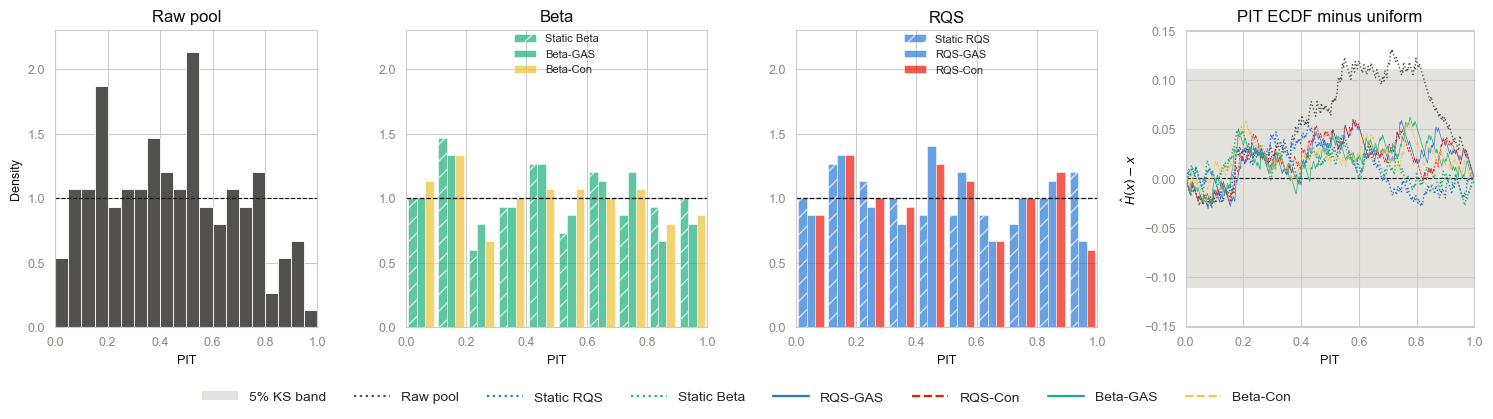

In [88]:
d = sr.DELTAS.index(0.9)
print(sr.scorecard_latex(results, d))     # Table B, main text
print(sr.robustness_latex(results))       # appendix
sr.pit_grid(results, d, "figures/inflation/inflation.pdf")

In [85]:
# localised metrics around the 2% target band, delta = 0.95 (as in your original cell)
res_loc = evaluate_localized(
    x=x_grid, y=y, pit_data=pit_values, cdf_data=cdfs,
    methods={**METHODS, **STATIC_LOC}, discount_factor=0.95,
    eval_start=EVAL_START, min_events=15, n_blocks=2,
    threshold_window='auto', target=2.0, radii=(1.0,))


LOCALIZED EVALUATION   base pool = pit_data row 2   discount factor 0.95
  window [0,150)   n=150   offset 0   max |PIT_grid - PIT_stored| = 0.00e+00
  regions (rolling 48 thresholds, n=150, min_events=15): tails q=0.1, 2 blocks
    realised counts -> left tail  q=0.1:48, right tail q=0.9:15, left tail  q=0.15:64, right tail q=0.85:17, block 1/2:110, block 2/2:40, band 2+-1:89, off band 2+-1:61

INPUT CHECKS
[discount factor 0.95   window [0,150)   n=150]
                               value
pool row                           2
offset                             0
window                       [0,150)
n                                150
max |PIT_grid - PIT_stored|   0.0000
KS PIT stored                 0.1322
KS PIT grid                   0.1322
grid mass                     1.0000
obs outside grid              0.0000

MASTER TABLE -- levels  (delta = gain over the raw pool, POSITIVE ALWAYS MEANS BETTER; HAC t-stat stars)
[discount factor 0.95   window [0,150)   n=150]
               

In [86]:
d = sr.DELTAS.index(0.9)
tex = sr.scorecard_latex(results, d, caption=(
    r"US inflation, LDF discount factor $\delta=0.9$, evaluation window "
    rf"$[{EVAL_START},{len(y)})$. KS: Kolmogorov--Smirnov distance of the PIT from uniform "
    r"($^\dagger$ rejects at 5\%). Raw pool: level of each score; method columns: gain over the raw "
    r"pool, positive is better. Stars: HAC Giacomini--White test at 10/5/1\%. Static RQS, Static Beta: "
    r"expanding-window static maps. Best method in bold."))
print(tex)
open("tables/inflation_scores.tex", "w").write(tex)

\begin{table}[H]\centering\small
\begin{tabular}{llccccccc}\toprule
Scenario & Metric & Raw pool & Static RQS & RQS-GAS & RQS-Con & Static Beta & Beta-GAS & Beta-Con \\ \midrule
inflation & KS & $0.132^{\dagger}$ & $0.056$ & $0.061$ & $0.062$ & $\mathbf{0.051}$ & $0.064$ & $0.062$ \\
 & LogS & $-0.1656$ & $-0.0448$ & $+0.0131$ & $+0.0123$ & $\mathbf{+0.0324}$ & $+0.0256$ & $+0.0287$ \\
 & CRPS & $0.1591$ & $+0.0026$ & $+0.0015$ & $+0.0021$ & $\mathbf{+0.0031}$ & $+0.0001$ & $+0.0014$ \\
 & IS$_{90}$ & $1.2326$ & $+0.0177$ & $+0.0265^{**}$ & $+0.0334^{***}$ & $+0.0142$ & $+0.0563^{**}$ & $\mathbf{+0.0580^{*}}$ \\
 & IS$_{95}$ & $1.4559$ & $+0.0812$ & $+0.0357^{***}$ & $+0.0360^{**}$ & $+0.0576$ & $\mathbf{+0.1248^{***}}$ & $+0.0913^{*}$ \\
 & CSL$_{L}$ & $-0.1182$ & $-0.0140$ & $+0.0121$ & $+0.0162$ & $\mathbf{+0.0442^{*}}$ & $+0.0259^{*}$ & $+0.0230$ \\
 & CSL$_{R}$ & $-0.1281$ & $-0.0226$ & $-0.0011$ & $-0.0047$ & $-0.0178$ & $-0.0043$ & $\mathbf{+0.0018}$ \\
\bottomrule\end{tabular}


1423